# Is our outside data like the Kaggle data?

The first notebook (`data_story.ipynb`) looked only at Kaggle's `train.csv`: 2,699 texts.

That is far too little to train a big model, so our models first learn from **outside (external) data** that other people collected and shared publicly. Then they get a short "polish" on `train.csv`.

This notebook asks: **does the outside data behave like the Kaggle data?** If it doesn't, the model learns habits that don't help on the real test.

**The three datasets**

| Name here | What it is | Rows | Used for |
|---|---|---|---|
| **Kaggle** | `train.csv` from the competition | 2,699 | stage 2 (the polish) and all scoring |
| **Open pool** | `pool_typo_60k`: 60,000 texts picked from a big community pool (many Kaggle users' generated sets), filtered to match Kaggle's punctuation style | 60,000 | stage 1 of all our Qwen models |
| **Hostlike** | prvsiyan's extended dataset: one person sent ~800 new prompts to all 18 models, logging every call | 6,897 | added to stage 1 for some models (k_host, the 8B) |

**Colours:** in this notebook the colour of a **dot** means the **dataset**:
- **black** is Kaggle
- **violet** is the open pool
- **red** is hostlike

Model names stay coloured by family, like before.

In [1]:
import re, collections
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, TwoSlopeNorm
from matplotlib.lines import Line2D

ROOT = "../"
D = {
    "Kaggle": pd.read_csv(ROOT + "data/train.csv"),
    "Open pool": pd.read_parquet(ROOT + "data/processed/pool_typo_60k.parquet"),
    "Hostlike": pd.read_parquet(ROOT + "data/processed/hostlike.parquet"),
}
for d in D.values(): d["text"] = d.text.fillna("").astype(str)
DS_COLOR = {"Kaggle": "#222222", "Open pool": "#6250d6", "Hostlike": "#e34948"}
DS_MARK = {"Kaggle": "o", "Open pool": "s", "Hostlike": "^"}

FAMILIES = ["claude", "gemini", "gpt", "glm", "kimi", "qwen"]
FAM_COLOR = dict(zip(FAMILIES, ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300"]))
fam = lambda m: next(f for f in FAMILIES if m.startswith(f))
MODELS = sorted(D["Kaggle"].model.unique(), key=lambda m: (FAMILIES.index(fam(m)), m))
DIV = LinearSegmentedColormap.from_list("div", ["#1c5cab", "#86b6ef", "#ecebe6", "#f3a17f", "#b8431a"])
plt.rcParams.update({"figure.facecolor": "white", "axes.facecolor": "white", "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
ds_legend = [Line2D([], [], marker=DS_MARK[k], color=DS_COLOR[k], ls="", ms=8, label=k) for k in D]

def colour_labels(ax, axis="y"):
    for lab in (ax.get_yticklabels() if axis == "y" else ax.get_xticklabels()):
        lab.set_color(FAM_COLOR[fam(lab.get_text())]); lab.set_fontweight("bold")

for k, d in D.items(): print(f"{k:10s} {len(d):6d} texts, {d.model.nunique()} models")

Kaggle       2699 texts, 18 models
Open pool   60000 texts, 18 models
Hostlike     6897 texts, 18 models


## 1. How many texts per model?

In Kaggle every model has 150 texts. Here are the same counts for the outside data, as a **share** of each dataset (so a small and a big dataset can share one chart).

If everything were perfectly fair, every model would sit at 1/18, about 5.6% (the dotted line).

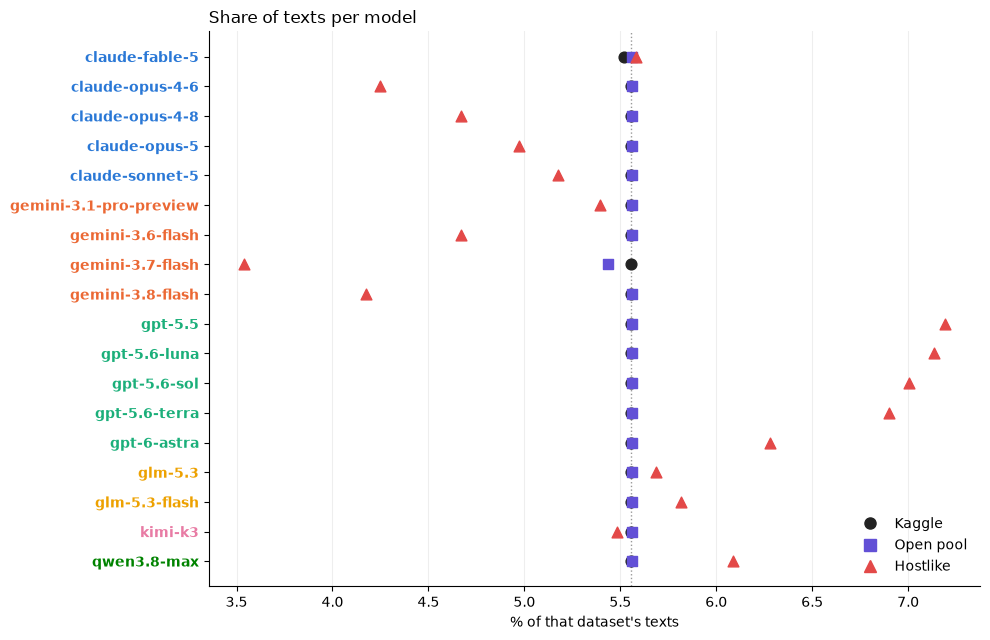

In [2]:
fig, ax = plt.subplots(figsize=(10, 6.5))
for k, d in D.items():
    share = d.model.value_counts(normalize=True).reindex(MODELS).fillna(0) * 100
    ax.scatter(share, range(len(MODELS)), marker=DS_MARK[k], color=DS_COLOR[k], s=60, label=k, zorder=3)
ax.axvline(100 / 18, color="#999", ls=":", lw=1)
ax.set_yticks(range(len(MODELS)), MODELS); ax.invert_yaxis(); colour_labels(ax)
ax.set_xlabel("% of that dataset's texts"); ax.grid(axis="x", color="#eee"); ax.set_axisbelow(True)
ax.legend(handles=ds_legend, frameon=False, loc="lower right"); ax.set_title("Share of texts per model", loc="left")
plt.tight_layout(); plt.show()

**What this shows:**
- The **open pool** was sampled to be perfectly balanced, so its dots sit right on the dotted line, like Kaggle.
- **Hostlike** is uneven. GPT models have the most texts (about 7%). **gemini-3.7-flash has the fewest (3.5%)**. Remember, that is exactly the model we recognise worst.

## 2. Where does the outside data come from?

The open pool is a mix of many people's shared datasets. Hostlike is one person's dataset, but the calls went through different "routes" (APIs).

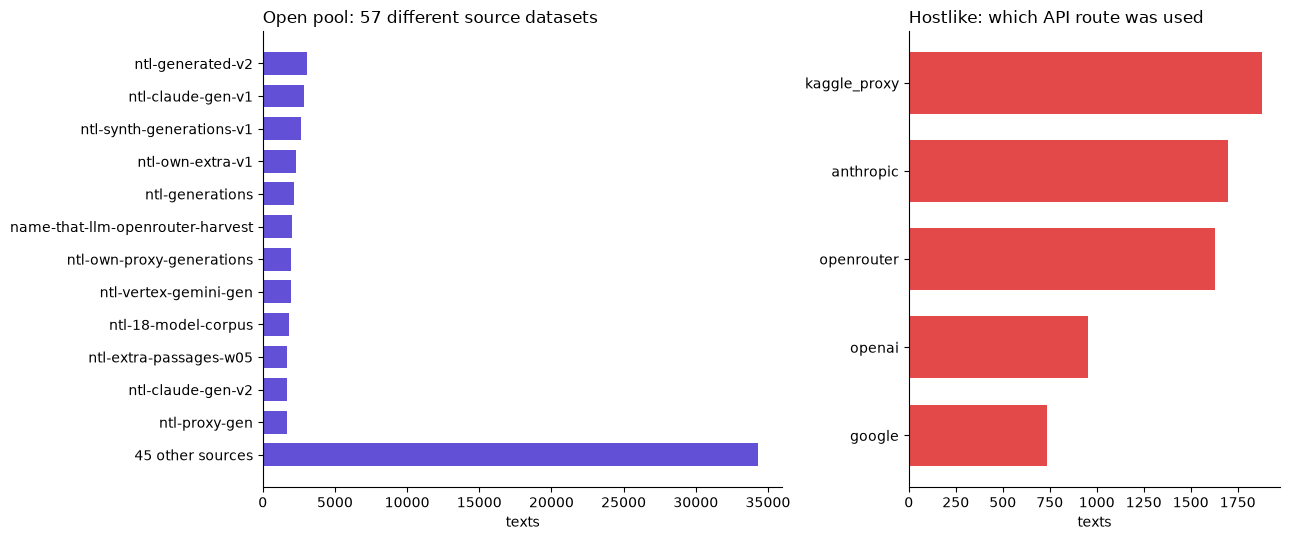

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), gridspec_kw={"width_ratios": [1.4, 1]})
src = D["Open pool"].source_dataset.str.split("/").str[-1].value_counts()
top = pd.concat([src.head(12), pd.Series({f"{len(src) - 12} other sources": src.iloc[12:].sum()})])
axes[0].barh(top.index[::-1], top.values[::-1], color=DS_COLOR["Open pool"], height=0.7)
axes[0].set_title(f"Open pool: {len(src)} different source datasets", loc="left"); axes[0].set_xlabel("texts")
rt = D["Hostlike"].provider_route.value_counts()
axes[1].barh(rt.index[::-1], rt.values[::-1], color=DS_COLOR["Hostlike"], height=0.7)
axes[1].set_title("Hostlike: which API route was used", loc="left"); axes[1].set_xlabel("texts")
plt.tight_layout(); plt.show()

**What this shows:** the open pool is a **patchwork** of many different people's generated texts. Each person used their own prompts and settings. That makes it varied, but also means some parts may not look like Kaggle's texts.

Hostlike is more controlled: one person, one method, and the served model was checked for every call.

## 3. Are the prompts the same? (texts per prompt)

In Kaggle every prompt was answered by **all 18 models**. Because the topic is the same for all of them, the only clue is the writing style.

How many models answered the same prompt in the outside data?

Kaggle     prompts    150 | median models per prompt 18 | prompts with all 18: 99%
Open pool  prompts 15,165 | median models per prompt 2 | prompts with all 18: 0%
Hostlike   prompts    598 | median models per prompt 13 | prompts with all 18: 14%


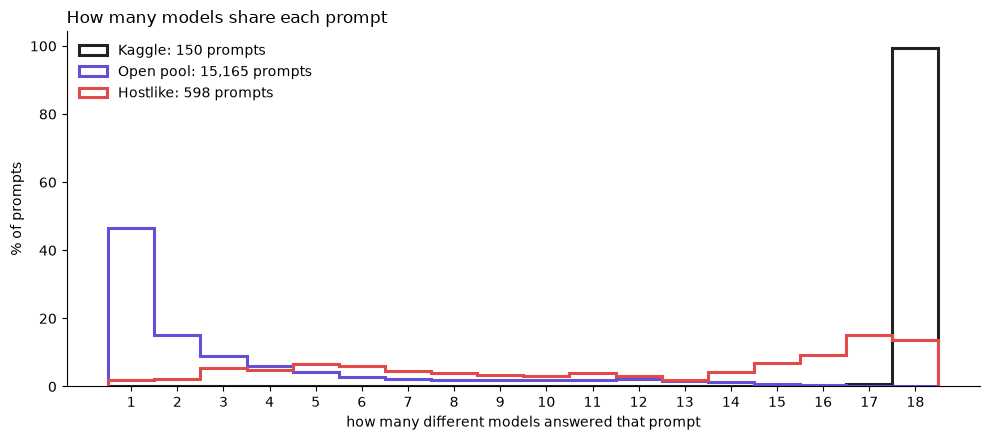

In [4]:
grp = {"Kaggle": D["Kaggle"].prompt_id,
       "Open pool": D["Open pool"].prompt_canon.fillna(D["Open pool"].prompt_group),
       "Hostlike": D["Hostlike"].prompt_group}
fig, ax = plt.subplots(figsize=(10, 4.5))
bins = np.arange(0.5, 19.5)
for k, g in grp.items():
    n_models = D[k].groupby(g.values).model.nunique()
    ax.hist(n_models, bins=bins, weights=np.full(len(n_models), 100 / len(n_models)), histtype="step", lw=2.2,
            color=DS_COLOR[k], label=f"{k}: {len(n_models):,} prompts")
    print(f"{k:10s} prompts {len(n_models):6,} | median models per prompt {n_models.median():.0f} | "
          f"prompts with all 18: {(n_models == 18).mean():.0%}")
ax.set_xticks(range(1, 19)); ax.set_xlabel("how many different models answered that prompt")
ax.set_ylabel("% of prompts"); ax.legend(frameon=False); ax.set_title("How many models share each prompt", loc="left")
plt.tight_layout(); plt.show()

**What this shows:**
- **Kaggle** is one tall bar at 18: almost every prompt was answered by every model.
- **Open pool** is the opposite. Almost half its prompts were answered by **only one model**. So in the pool, the *topic* can secretly give away the model. For example, if one person only asked Claude about volcanoes, a model can learn "volcano means Claude". That shortcut is useless on Kaggle's test.
- **Hostlike** is in between. Most prompts were answered by 13 to 18 models, so it is much closer to Kaggle's "same topic for everyone" design.

## 4. Are the prompts the same? (do outside texts talk about Kaggle's topics?)

Kaggle doesn't give us the prompt text itself, only an id like `p081`. So we compare the **texts**:
1. For every outside text, find the Kaggle text with the **most similar words**.
2. Measure how similar they are (0 = no shared words, 1 = identical). This is "TF-IDF cosine similarity", which mostly looks at the topic words.

To know what the numbers mean, we need two rulers taken from Kaggle itself:
- **Same prompt:** two Kaggle texts that answer the *same* prompt (different models). This is what "same topic" looks like.
- **Different prompts:** the closest Kaggle text from a *different* prompt. This is what "unrelated topic" looks like.

If the outside texts sit with the "different prompts" ruler, they are **not** about Kaggle's prompts.

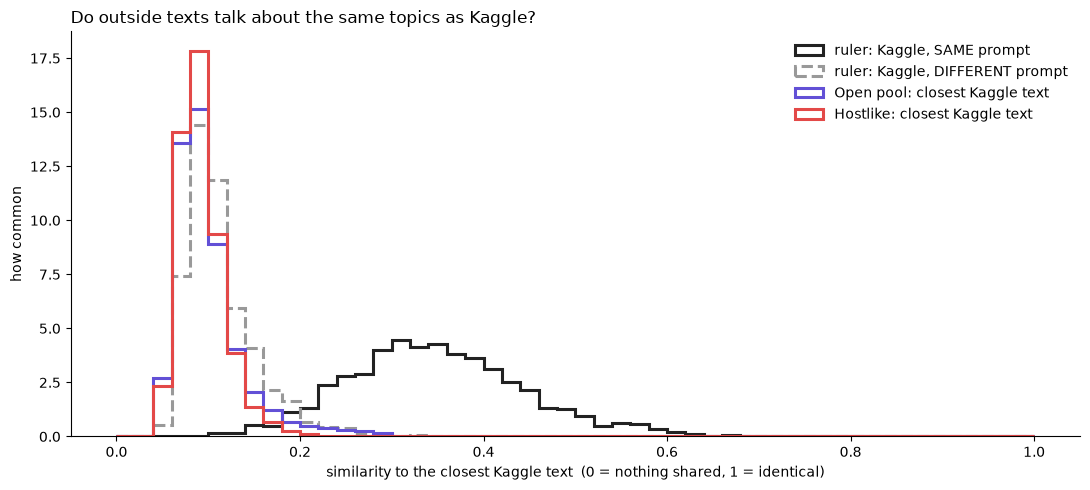

typical similarity: same prompt 0.34 | different prompt 0.10
Open pool  median 0.09 | max 0.32 | above the 'same prompt' level (0.20): 3.19%
Hostlike   median 0.09 | max 0.41 | above the 'same prompt' level (0.20): 0.39%


In [5]:
from sklearn.feature_extraction.text import TfidfVectorizer
rng = np.random.default_rng(0)
K = D["Kaggle"]
pool_s = D["Open pool"].iloc[rng.choice(len(D["Open pool"]), 20000, replace=False)]   # a 20k sample keeps it quick
vec = TfidfVectorizer(stop_words="english", sublinear_tf=True, min_df=2).fit(pd.concat([K.text, pool_s.text, D["Hostlike"].text]))
Xk = vec.transform(K.text)
S = (Xk @ Xk.T).toarray(); np.fill_diagonal(S, -1)
same = K.prompt_id.to_numpy()[:, None] == K.prompt_id.to_numpy()[None, :]
ruler_same = np.where(same, S, -1).max(1)               # best match inside its own prompt
ruler_diff = np.where(~same, S, -1).max(1)              # best match from any other prompt
best = {"Open pool": (vec.transform(pool_s.text) @ Xk.T).max(1).toarray().ravel(),
        "Hostlike": (vec.transform(D["Hostlike"].text) @ Xk.T).max(1).toarray().ravel()}
fig, ax = plt.subplots(figsize=(11, 5))
bins = np.linspace(0, 1, 51)
kw = dict(bins=bins, histtype="step", lw=2.2, density=True)
ax.hist(ruler_same, color="#222", ls="-", label="ruler: Kaggle, SAME prompt", **kw)
ax.hist(ruler_diff, color="#999", ls="--", label="ruler: Kaggle, DIFFERENT prompt", **kw)
for k, v in best.items(): ax.hist(v, color=DS_COLOR[k], label=f"{k}: closest Kaggle text", **kw)
ax.set_xlabel("similarity to the closest Kaggle text  (0 = nothing shared, 1 = identical)"); ax.set_ylabel("how common")
ax.legend(frameon=False); ax.set_title("Do outside texts talk about the same topics as Kaggle?", loc="left")
plt.tight_layout(); plt.show()
cut = np.quantile(ruler_same, 0.05)   # 95% of same-prompt Kaggle pairs are above this
print(f"typical similarity: same prompt {np.median(ruler_same):.2f} | different prompt {np.median(ruler_diff):.2f}")
for k, v in best.items():
    print(f"{k:10s} median {np.median(v):.2f} | max {v.max():.2f} | above the 'same prompt' level ({cut:.2f}): {np.mean(v > cut):.2%}")

**What this shows: no, the prompts are not the same.**
- The violet and red outside curves sit right on top of the grey **"different prompt"** ruler, far left of the black **"same prompt"** ruler.
- Even the single closest outside text (max about 0.3 to 0.4) is only as close as an average same-prompt pair.
- A few percent of open pool texts pass the "same prompt" line. Those are texts on a *nearby* topic (say, another black-hole explanation), not copies of Kaggle prompts.

This was deliberate. The pool was built to remove anything too close to Kaggle's prompts (its `flag_near_train_prompt` column is 0 for every row), and the hostlike author says no competition prompt was used.

**Why that matters:**
- **Good news: no cheating.** Our out-of-fold scores are honest, because the model never saw Kaggle's topics during stage 1.
- **Bad news:** stage 1 learns style on *other* topics. Kaggle's own texts are needed to adjust it, which is exactly what stage 2 does. That's also why stage 2 gives us about +7 to 8 points.

## 5. Do the outside texts look the same on the page?

Kaggle texts are always **one plain paragraph**: no headings, no bullet points, no line breaks.

Next: the same simple habits from the first notebook, for each dataset.

In [6]:
def habits(d):
    x = d.text; wc = x.str.split().str.len().clip(lower=1)
    return pd.DataFrame({
        "model": d.model,
        "em dash — per 1k words": x.str.count("—") / wc * 1000,
        "% with curly quotes": x.str.contains("[’“”]") * 100.0,
        "colon : per 1k words": x.str.count(":") / wc * 1000,
        "semicolon ; per 1k words": x.str.count(";") / wc * 1000,
        "words per text": wc,
        "words per sentence": x.apply(lambda s: len(s.split()) / max(1, len(re.findall(r"[.!?](\s|$)", s)))),
        "% with line breaks": x.str.contains("\n") * 100.0,
        "% with markdown (# * -)": x.str.contains(r"(?m)^\s*(?:#|[-*] )|\*\*") * 100.0,
    })
H = {k: habits(d) for k, d in D.items()}
overall = pd.DataFrame({k: h.drop(columns="model").mean() for k, h in H.items()}).round(1)
overall

,Kaggle,Open pool,Hostlike
em dash — per 1k words,6.3,5.8,7.9
% with curly quotes,22.5,28.8,34.6
colon : per 1k words,6.0,5.1,6.4
semicolon ; per 1k words,4.1,3.2,3.8
words per text,114.7,113.5,101.6
words per sentence,24.1,22.5,22.0
% with line breaks,0.0,0.0,0.0
% with markdown (# * -),0.0,0.0,0.0


**What the table shows:**
- On average, the three datasets look similar: the same rough rates of dashes, colons and semicolons, and all are one plain paragraph (0% line breaks and 0% markdown).
- That is no accident: the open pool was picked and cleaned to match Kaggle's typography.
- Two differences stand out:
  - **Curly quotes** are more common outside (29% and 35% of texts, against 22.5% in Kaggle).
  - **Hostlike texts are shorter** (about 102 words against 115).
- But averages can hide a lot. The next chart looks model by model.

**How to read the table:** each row is one habit, each column a dataset (the average over all of its texts). Compare the columns side by side: are the numbers close?

## 6. The style fingerprint, model by model

This is the most important comparison. For each habit:
- every model has **three dots**: black for Kaggle, violet for the open pool, red for hostlike
- a thin grey line joins them

**Short lines** mean the outside data copies Kaggle's habit well. **Long lines** mean the outside data teaches the model a *different* habit than the one it will see in the test.

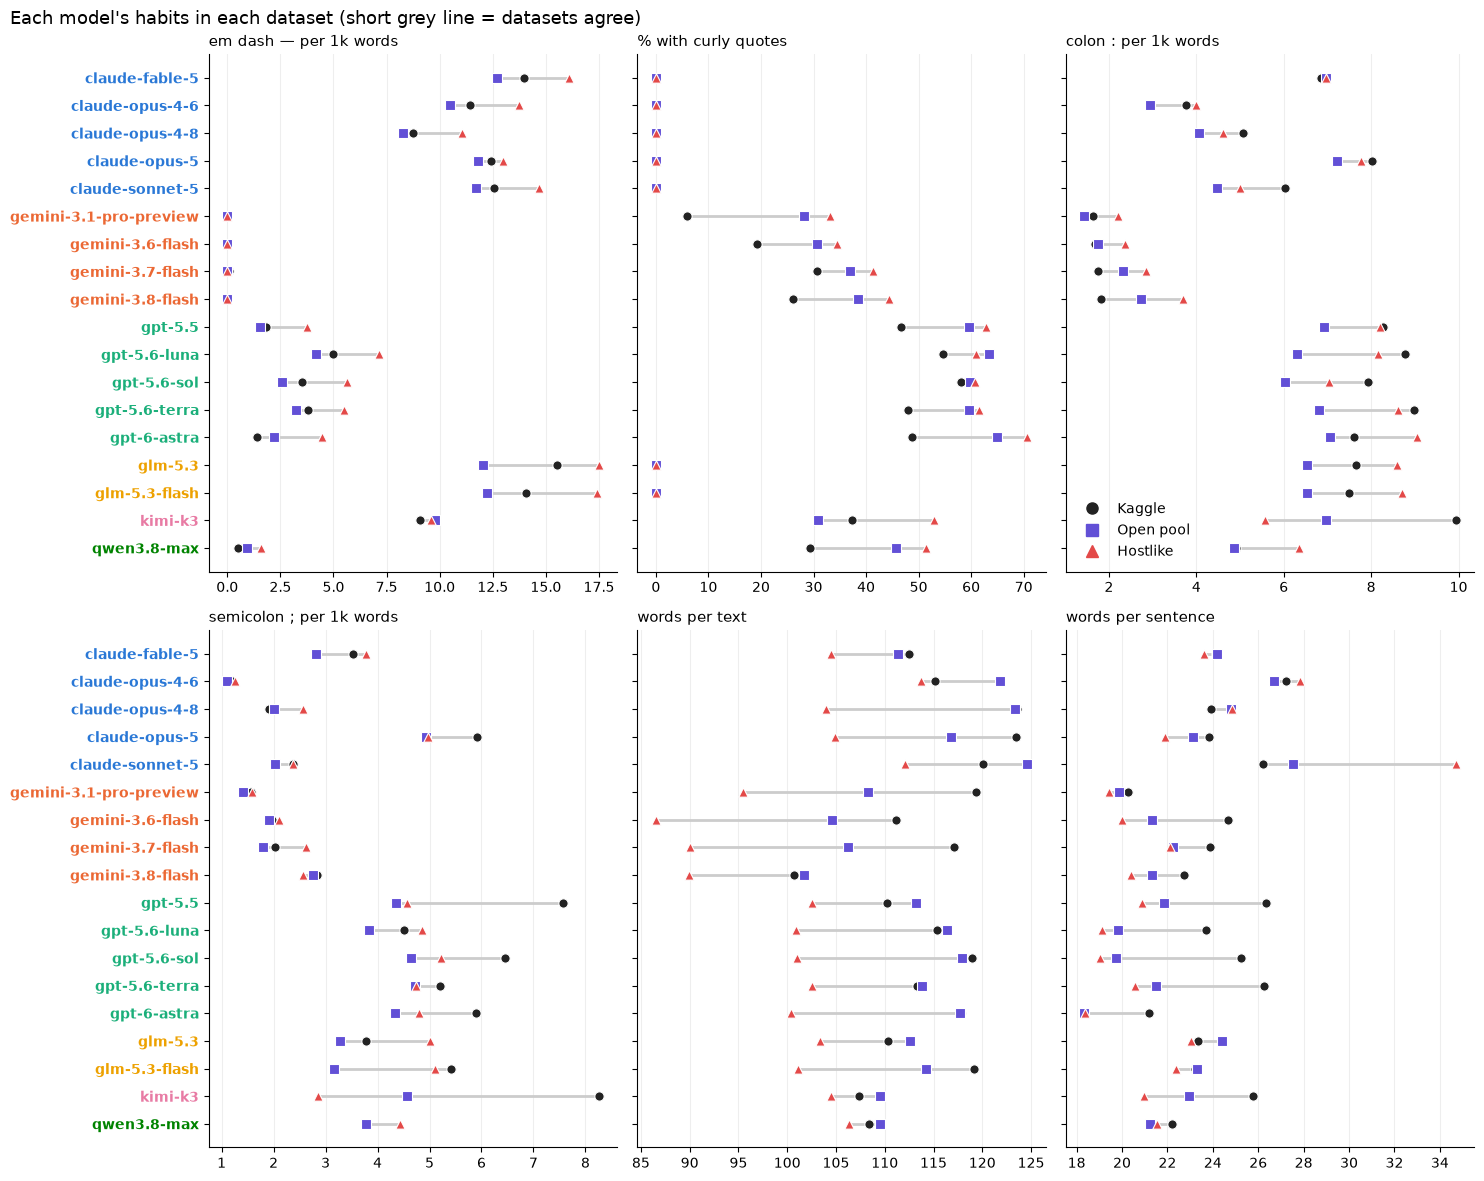

In [7]:
cols = ["em dash — per 1k words", "% with curly quotes", "colon : per 1k words",
        "semicolon ; per 1k words", "words per text", "words per sentence"]
M = {k: h.groupby("model")[cols].mean().reindex(MODELS) for k, h in H.items()}
fig, axes = plt.subplots(2, 3, figsize=(15, 12), sharey=True)
for ax, c in zip(axes.ravel(), cols):
    vals = np.column_stack([M[k][c] for k in D])
    for i in range(len(MODELS)):
        ax.plot([np.nanmin(vals[i]), np.nanmax(vals[i])], [i, i], color="#ccc", lw=2, zorder=1)
    for k in D:
        ax.scatter(M[k][c], range(len(MODELS)), marker=DS_MARK[k], color=DS_COLOR[k], s=45, zorder=3,
                   edgecolor="white", lw=0.8)
    ax.set_title(c, loc="left", fontsize=11); ax.grid(axis="x", color="#eee"); ax.set_axisbelow(True)
    ax.set_yticks(range(len(MODELS)), MODELS)
axes[0, 0].invert_yaxis()   # shared y axis: invert once
for ax in axes[:, 0]: colour_labels(ax)
axes[0, 2].legend(handles=ds_legend, frameon=False, loc="lower left")
fig.suptitle("Each model's habits in each dataset (short grey line = datasets agree)", x=0.01, ha="left", fontsize=13)
plt.tight_layout(); plt.show()

**What this shows:**

**The rules hold everywhere.**
- Claude and GLM have **0% curly quotes** in all three datasets.
- Gemini has **no em dashes** in all three.
- So the "family clues" from the first notebook are real habits of the models, not quirks of Kaggle's data.

**The sizes drift.** These are the places where the outside data teaches a habit that does not match Kaggle:
- **Curly quotes in gemini-3.1-pro:** only 6% of its Kaggle texts, but about 30% outside. GPT and Qwen also use more curly quotes outside.
- **Kimi's semicolons:** 8.3 per 1k words in Kaggle, but 4.6 in the pool and 2.9 in hostlike. Kaggle's Kimi behaves differently from outside Kimi, which may be one reason Kimi is often mistaken for GPT.
- **GPT's sentences:** longer in Kaggle (24 to 26 words) than outside (18 to 22).
- **Length:** hostlike texts are shorter for nearly every model, and the Geminis most of all (87 to 95 words against 101 to 119).
- **A clue the outside data hides:** in Kaggle, **gemini-3.7-flash writes longer texts (117 words) than gemini-3.8-flash (101)**. Outside, the two are almost the same length. So our stage-1 model never learns "longer means 3.7", and the 3.7 vs 3.8 mix-up is our worst error. Only the 150 Kaggle texts per model can teach that clue.

These drifts probably come from different settings (length limits, system prompts, API routes, dates). The same model can write a bit differently depending on how it is called.

## 7. Do the models keep their favourite words?

In the first notebook every model had pet words. Do they keep the **same** pet words in the outside data?

For each model we take every common word and work out "how much more or less than other models it uses it":
- once in Kaggle
- once in each outside dataset

Then we check whether the two lists **agree**:
- **1.0** means the model has exactly the same word taste in both
- **0** means no relation at all

Note: Kaggle has only 150 texts per model, so even a perfect copy would not reach 1.0. Think of 0.5 and up as "clearly the same taste".

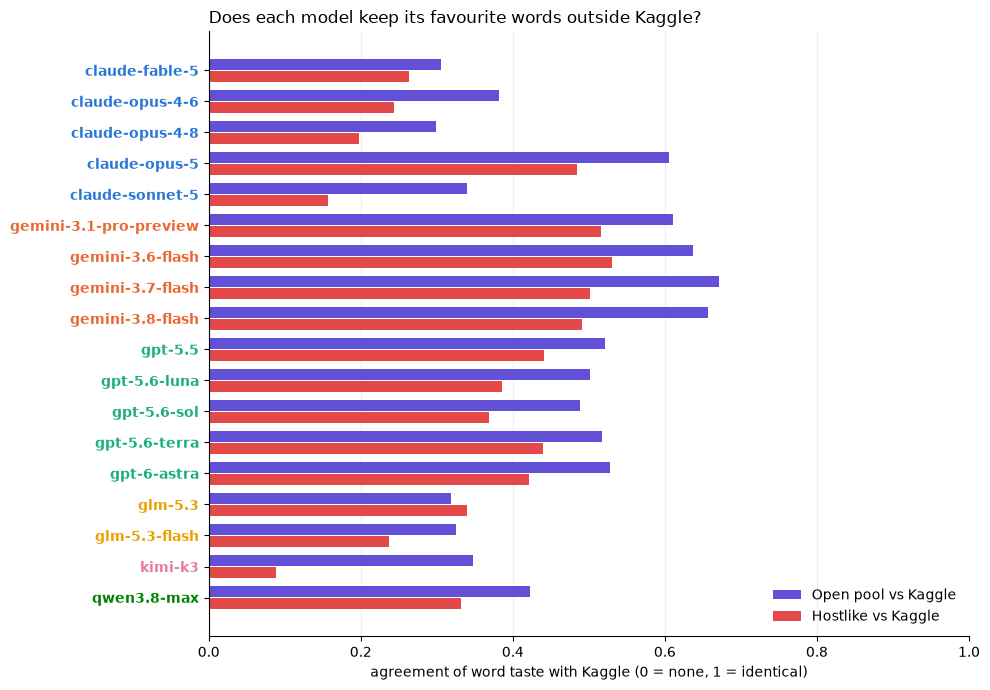

Open pool    0.47
Hostlike     0.36


In [8]:
def word_ratio(d):
    tok = d.text.str.lower().str.replace("’", "'").str.findall(r"[a-z]+(?:'[a-z]+)?")
    cnt = {m: collections.Counter(w for ws in tok[d.model == m] for w in ws) for m in MODELS}
    rate = pd.DataFrame({m: {w: c / max(1, sum(cnt[m].values())) for w, c in cnt[m].items()} for m in MODELS}).fillna(0)
    return rate, np.log2((rate + 2e-5).div(rate.mean(axis=1) + 2e-5, axis=0))
rate_k, ratio_k = word_ratio(D["Kaggle"])
common = rate_k.index[(rate_k * 150 * 100).sum(axis=1) >= 30]          # words used at least ~30 times in Kaggle
agree = {}
for k in ["Open pool", "Hostlike"]:
    _, r = word_ratio(D[k] if k == "Hostlike" else D[k].groupby("model").sample(1500, random_state=0))
    w = common.intersection(r.index)
    agree[k] = pd.Series({m: np.corrcoef(ratio_k.loc[w, m], r.loc[w, m])[0, 1] for m in MODELS})
A = pd.DataFrame(agree)
fig, ax = plt.subplots(figsize=(10, 7))
y = np.arange(len(MODELS))
for j, k in enumerate(A.columns):
    ax.barh(y + (j - 0.5) * 0.38, A[k], height=0.36, color=DS_COLOR[k], label=f"{k} vs Kaggle")
ax.set_yticks(y, MODELS); ax.invert_yaxis(); colour_labels(ax)
ax.set_xlim(0, 1); ax.set_xlabel("agreement of word taste with Kaggle (0 = none, 1 = identical)")
ax.grid(axis="x", color="#eee"); ax.set_axisbelow(True); ax.legend(frameon=False, loc="lower right")
ax.set_title("Does each model keep its favourite words outside Kaggle?", loc="left")
plt.tight_layout(); plt.show()
print(A.mean().round(2).to_string())

**What this shows:**
- **The open pool agrees more with Kaggle than hostlike does** (average about 0.47 against 0.36). That fits our experiments: adding hostlike to stage 2 made scores worse (about -3 points).
- **The Geminis keep their word taste best** (about 0.6 to 0.7). Gemini is also the family we never confuse with other families.
- **Claude (except opus-5), GLM and Kimi keep it worst** (about 0.1 to 0.35). Kimi in hostlike is almost unrelated (0.09). These are exactly the models we mix up most (Claude with GLM, and Kimi with GPT).

So **where the outside data matches Kaggle, our model is good. Where it doesn't, our model struggles.** That's a strong hint about where better data would help.

## 8. Do the families look alike in the same way?

In the first notebook, the "who writes alike" grid showed family squares: the Geminis were near twins, and GLM looked like Claude. Here is the same grid, side by side, for Kaggle and the open pool.

**How to read it:**
- **Orange** means the two models write alike.
- **Blue** means they write differently.

If the two grids show the same pattern, the open pool teaches the right "family map".

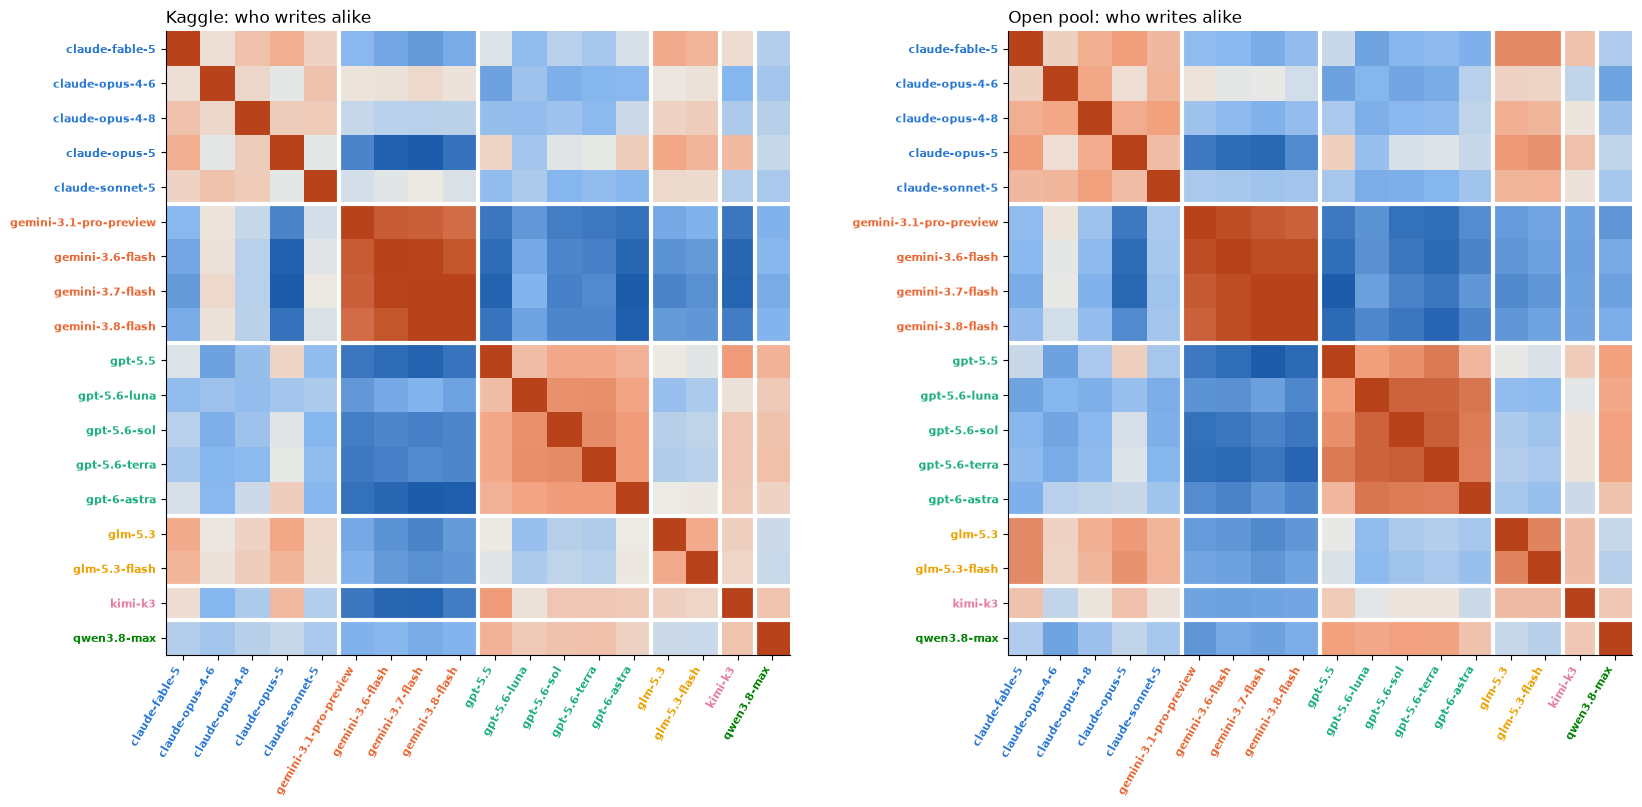

how well the two grids match (0 = not at all, 1 = identical): 0.95


In [9]:
def sim_grid(d):
    X = TfidfVectorizer(analyzer="char_wb", ngram_range=(3, 5), min_df=5, sublinear_tf=True,
                        max_features=60000).fit_transform(d.text)
    c = np.vstack([np.asarray(X[(d.model == m).to_numpy()].mean(0)).ravel() for m in MODELS])
    c -= c.mean(0); c /= np.linalg.norm(c, axis=1, keepdims=True)
    return c @ c.T
G = {"Kaggle": sim_grid(D["Kaggle"]),
     "Open pool": sim_grid(D["Open pool"].groupby("model").sample(1000, random_state=0))}
fig, axes = plt.subplots(1, 2, figsize=(17, 8))
for ax, (k, g) in zip(axes, G.items()):
    off = g[~np.eye(len(MODELS), dtype=bool)]
    ax.imshow(g, cmap=DIV, norm=TwoSlopeNorm(0, off.min(), off.max()))
    ax.set_xticks(range(len(MODELS)), MODELS, rotation=60, ha="right", fontsize=8)
    ax.set_yticks(range(len(MODELS)), MODELS, fontsize=8); colour_labels(ax); colour_labels(ax, "x")
    edges = np.cumsum([sum(fam(m) == f for m in MODELS) for f in FAMILIES])[:-1] - 0.5
    for e in edges: ax.axhline(e, color="white", lw=3); ax.axvline(e, color="white", lw=3)
    ax.set_title(f"{k}: who writes alike", loc="left")
plt.tight_layout(); plt.show()
iu = np.triu_indices(len(MODELS), 1)
print(f"how well the two grids match (0 = not at all, 1 = identical): {np.corrcoef(G['Kaggle'][iu], G['Open pool'][iu])[0, 1]:.2f}")

**What this shows:** the two grids are **almost the same picture**. The match score is 0.95, where 1.0 would be identical.
- Gemini is a dark square in both.
- GPT is a clear square in both.
- GLM sits next to Claude in both. In the open pool the GLM and Claude closeness is even stronger.

So the *big* map of who-resembles-whom is the same everywhere. The outside data teaches the families correctly, and the problems are in the fine details (chart 6).

## Summary: answers to your questions

| Question | Answer |
|---|---|
| Are the prompts the same as Kaggle's? | **No.** Both outside sets were built to avoid Kaggle's prompts, and the similarity check (chart 4) confirms it. |
| Is each prompt answered by every model? | Kaggle: yes. Hostlike: mostly. Open pool: **no**, half its prompts have just one model, so topic can act as a false clue there. |
| Do the big family rules hold outside? | **Yes.** Claude and GLM never use curly quotes, Gemini never uses em dashes, and the family map matches 0.95. |
| Do the fine details match? | **Only partly.** Rates of curly quotes, semicolons, sentence length and text length drift. Some useful Kaggle clues, like 3.7 being longer than 3.8, are missing outside. |
| Which outside set is more Kaggle-like? | The **open pool** matches word taste better (0.47 against 0.36). Hostlike has the better prompt design (many models per prompt), but is shorter and drifts more. |

**Big picture:** outside data is great for learning the **families**. But the **sibling differences** that Kaggle's test needs are partly *different* outside. That's why the short stage 2 on Kaggle's own 2,699 texts is so important, and why the remaining errors sit among the siblings.